# Prédiction de la variable de qualité

**Peut-on prévoir le profil de résistance d'une soudure à partir de sa composition et de ses paramètres de fabrication ?**

Deux classes : **0 = résistance modérée**, **1 = résistance élevée**. La qualité désigne ici un profil mécanique dont l'intérêt dépend de l'application.

```text
Propriétés mécaniques Y → ACP + clustering → classe attendue
Composition et procédé X → classifieur    → classe prédite
```

| Parcours | Question |
|---|---|
| 1–3 · Préparer les données | Quelles soudures et quelles classes ? |
| 4–5 · Comparer les modèles | Quel classifieur apprend le mieux ? |
| 6–7 · Évaluer et interpréter | Réussit-il sur de nouvelles soudures ? |

**Lecture rapide :** suivre les textes, les tableaux et les graphiques. Pour reproduire l'analyse, exécuter les cellules dans l'ordre.

In [23]:
from pathlib import Path
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
N_SPLITS_CV = 5
sns.set_theme(style="whitegrid", context="notebook")


## 1. Quelles données utilise-t-on ?

**Point de départ :** le dataset prétraité. On conserve les lignes avec les quatre propriétés mécaniques disponibles : limite d'élasticité, résistance maximale, élongation et réduction de section.

**À lire ci-dessous :** le nombre de lignes retenues et de `Weld ID` distincts.

In [24]:
DATA_CANDIDATES = [
    Path("1. Données/02_intermediate/welddb_processed_vf.csv"),
    Path("../1. Données/02_intermediate/welddb_processed_vf.csv"),
]
DATA_PATH = next(path for path in DATA_CANDIDATES if path.exists())
df = pd.read_csv(DATA_PATH, sep=";")

ID_COL = "Weld ID"
QUALITY_VARIABLES = [
    "Yield strength",
    "Ultimate tensile strength",
    "Elongation",
    "Reduction of Area",
]
EXCLUDED_OUTPUTS = QUALITY_VARIABLES + [
    "Charpy temperature",
    "Charpy impact toughness",
]

complete_mask = df[QUALITY_VARIABLES].notna().all(axis=1)
model_df = df.loc[complete_mask].copy()

print(f"Dataset complet : {len(df)} lignes")
print(
    f"Population classifiable : {len(model_df)} lignes, "
    f"{model_df[ID_COL].nunique()} Weld ID distincts"
)


Dataset complet : 1652 lignes
Population classifiable : 650 lignes, 82 Weld ID distincts


## 2. Comment définit-on la classe ?

**La recette du notebook 4 :** standardiser les quatre propriétés → ACP à deux axes → K-means à deux groupes.

La classe **1** est le groupe dont la moyenne des deux résistances standardisées est la plus élevée ; l'autre reçoit **0**. Cette règle donne un sens stable aux numéros des clusters.

Le code ci-dessous prépare cette recette. Elle sera ajustée sur le train à l'étape suivante.

In [25]:
class QualityLabeler:
    """Construit 0 = résistance modérée, 1 = résistance élevée."""

    def __init__(self, random_state=42):
        self.random_state = random_state

    def fit(self, Y):
        Y = Y[QUALITY_VARIABLES]
        self.scaler_ = StandardScaler().fit(Y)
        Y_scaled = self.scaler_.transform(Y)
        self.pca_ = PCA(n_components=2).fit(Y_scaled)
        scores = self.pca_.transform(Y_scaled)
        self.kmeans_ = KMeans(
            n_clusters=2, n_init=50, random_state=self.random_state
        ).fit(scores)

        raw_labels = self.kmeans_.labels_
        scaled_df = pd.DataFrame(Y_scaled, columns=QUALITY_VARIABLES)
        scaled_df["raw_cluster"] = raw_labels
        resistance = (
            scaled_df.groupby("raw_cluster")
            [["Yield strength", "Ultimate tensile strength"]]
            .mean().mean(axis=1)
        )
        self.high_resistance_cluster_ = int(resistance.idxmax())
        return self

    def predict(self, Y):
        Y_scaled = self.scaler_.transform(Y[QUALITY_VARIABLES])
        scores = self.pca_.transform(Y_scaled)
        raw_labels = self.kmeans_.predict(scores)
        return (raw_labels == self.high_resistance_cluster_).astype(int)

    def profile_centers(self):
        centers_scaled = self.pca_.inverse_transform(self.kmeans_.cluster_centers_)
        centers = self.scaler_.inverse_transform(centers_scaled)
        result = pd.DataFrame(centers, columns=QUALITY_VARIABLES)
        result["classe"] = (
            result.index == self.high_resistance_cluster_
        ).astype(int)
        return result.set_index("classe").sort_index()


## 3. Quelles soudures réserve-t-on au test ?

**Environ 20 % des `Weld ID` sont réservés à l'évaluation finale.** Toutes les lignes d'un même identifiant restent ensemble.

On sépare d'abord les données, puis on ajuste l'ACP et le clustering sur le **train**. Les propriétés du **test** permettent ensuite d'attribuer ses classes avec cette règle figée.

**À lire ci-dessous :** les effectifs, la proportion de classe 1 et les centres des profils reconstruits dans les unités d'origine.

In [26]:
outer_split = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=RANDOM_STATE
)
train_pos, test_pos = next(
    outer_split.split(model_df, groups=model_df[ID_COL])
)
train_df = model_df.iloc[train_pos].copy()
test_df = model_df.iloc[test_pos].copy()

labeler = QualityLabeler(RANDOM_STATE).fit(train_df[QUALITY_VARIABLES])
y_train = pd.Series(
    labeler.predict(train_df[QUALITY_VARIABLES]), index=train_df.index,
    name="high_resistance_profile",
)
y_test = pd.Series(
    labeler.predict(test_df[QUALITY_VARIABLES]), index=test_df.index,
    name="high_resistance_profile",
)

assert set(train_df[ID_COL]).isdisjoint(set(test_df[ID_COL]))
split_summary = pd.DataFrame({
    "lignes": [len(train_df), len(test_df)],
    "Weld ID": [train_df[ID_COL].nunique(), test_df[ID_COL].nunique()],
    "part de classe 1": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
display(split_summary.round(3))
print("Centres des deux profils appris uniquement sur le train :")
display(labeler.profile_centers().round(1))


,lignes,Weld ID,part de classe 1
train,515,65,0.338
test,135,17,0.385


Centres des deux profils appris uniquement sur le train :


,Yield strength,Ultimate tensile strength,Elongation,Reduction of Area
classe,,,,
0,449.5,537.9,29.1,76.4
1,580.7,683.9,21.3,64.6


## 4. Avec quelles variables prédit-on ?

**Entrées X : compositions chimiques et paramètres de soudage disponibles avant les essais.**

Les quatre propriétés mécaniques et les variables Charpy sont exclues. `Weld ID` sert uniquement aux découpages.

| Type de variable | Préparation dans chaque sous-train |
|---|---|
| Numérique | Compléter par la médiane, puis standardiser |
| Catégorielle | Compléter par la modalité la plus fréquente, puis encoder |

La pipeline enchaîne cette préparation et le classifieur.

In [27]:
PREDICTOR_COLUMNS = [
    column for column in model_df.columns
    if column not in EXCLUDED_OUTPUTS + [ID_COL]
]
X_train = train_df[PREDICTOR_COLUMNS].copy()
X_test = test_df[PREDICTOR_COLUMNS].copy()
groups_train = train_df[ID_COL].copy()

NUMERIC_COLUMNS = X_train.select_dtypes(include=np.number).columns.tolist()
CATEGORICAL_COLUMNS = [
    column for column in PREDICTOR_COLUMNS if column not in NUMERIC_COLUMNS
]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, NUMERIC_COLUMNS),
    ("categorical", categorical_pipe, CATEGORICAL_COLUMNS),
])

def make_pipeline(estimator):
    return Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", clone(estimator)),
    ])

print(f"{len(PREDICTOR_COLUMNS)} prédicteurs : "
      f"{len(NUMERIC_COLUMNS)} numériques et "
      f"{len(CATEGORICAL_COLUMNS)} catégoriels.")


25 prédicteurs : 22 numériques et 3 catégoriels.


**Vue de la pipeline :** les variables numériques et catégorielles suivent chacune leur préparation, puis sont réunies pour alimenter le classifieur. La régression logistique illustre ici la structure commune ; la dernière étape sera remplacée par le modèle testé. Cliquez sur les blocs pour consulter leurs paramètres.

In [28]:
from sklearn import config_context

pipeline_visualisation = make_pipeline(LogisticRegression(
    solver="liblinear", class_weight="balanced",
    max_iter=5000, random_state=RANDOM_STATE,
))
with config_context(display="diagram"):
    display(pipeline_visualisation)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

## 5. Quel classifieur choisir ?

**Règle de choix : la meilleure balanced accuracy en validation croisée.** Ce score donne le même poids aux deux classes : **0,50 pour une prédiction constante**, **1 pour une prédiction parfaite**.

| Modèle | Rôle |
|---|---|
| Modèle naïf | Prédire toujours la classe majoritaire : notre référence |
| Régression logistique | Apprendre une frontière linéaire ; L1 peut annuler des coefficients, L2 les réduit |
| Random Forest | Apprendre des seuils et des interactions avec des arbres |
| Extra Trees | Tester des arbres avec davantage d'aléa |

**Protocole :** cinq découpages du train avec des `Weld ID` séparés. À chaque fois, l'ACP, le clustering et le classifieur sont réappris sur le sous-train. La validation reçoit ses classes avec la règle obtenue.

Les labels construits sur tout le train servent à équilibrer les folds ; les labels évalués sont recalculés dans chaque fold.

**À lire dans le tableau :** la meilleure configuration de chaque famille et la référence naïve. L'écart-type décrit la variation entre les cinq folds ; ce n'est pas un intervalle de confiance.

In [29]:
def binary_scores(y_true, y_pred, y_proba):
    return {
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1_classe_1": f1_score(y_true, y_pred, zero_division=0),
        "précision_classe_1": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "rappel_classe_1": recall_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_proba),
    }

# Les labels provisoires servent seulement à équilibrer les folds ; ils ont
# été construits sans aucune observation du test final.
cv = StratifiedGroupKFold(
    n_splits=N_SPLITS_CV, shuffle=True, random_state=RANDOM_STATE
)
cv_splits = list(cv.split(X_train, y_train, groups_train))

def evaluate_estimator_cv(estimator):
    fold_rows = []
    for fold, (fit_pos, valid_pos) in enumerate(cv_splits, start=1):
        fit_df = train_df.iloc[fit_pos]
        valid_df = train_df.iloc[valid_pos]
        assert set(fit_df[ID_COL]).isdisjoint(set(valid_df[ID_COL]))

        fold_labeler = QualityLabeler(RANDOM_STATE + fold).fit(
            fit_df[QUALITY_VARIABLES]
        )
        y_fit = fold_labeler.predict(fit_df[QUALITY_VARIABLES])
        y_valid = fold_labeler.predict(valid_df[QUALITY_VARIABLES])

        fitted = make_pipeline(estimator).fit(
            fit_df[PREDICTOR_COLUMNS], y_fit
        )
        pred = fitted.predict(valid_df[PREDICTOR_COLUMNS])
        proba = fitted.predict_proba(valid_df[PREDICTOR_COLUMNS])[:, 1]
        fold_rows.append({
            "fold": fold,
            **binary_scores(y_valid, pred, proba),
        })
    return pd.DataFrame(fold_rows)


In [30]:
candidate_specs = []
for penalty, C in product(["l1", "l2"], [0.01, 0.1, 1.0, 10.0]):
    candidate_specs.append({
        "famille": "Régression logistique",
        "configuration": f"penalty={penalty}, C={C:g}",
        "estimator": LogisticRegression(
            penalty=penalty, C=C, solver="liblinear",
            class_weight="balanced", max_iter=5000,
            random_state=RANDOM_STATE,
        ),
    })

for family, estimator_class in [
    ("Random Forest", RandomForestClassifier),
    ("Extra Trees", ExtraTreesClassifier),
]:
    for max_depth, min_samples_leaf in product([None, 8], [2, 5]):
        candidate_specs.append({
            "famille": family,
            "configuration": (
                f"depth={max_depth}, leaf={min_samples_leaf}"
            ),
            "estimator": estimator_class(
                n_estimators=300, max_depth=max_depth,
                min_samples_leaf=min_samples_leaf, max_features="sqrt",
                class_weight="balanced", n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
        })

baseline_folds = evaluate_estimator_cv(DummyClassifier(strategy="prior"))
result_rows = []
for candidate_id, spec in enumerate(candidate_specs):
    fold_scores = evaluate_estimator_cv(spec["estimator"])
    result_rows.append({
        "candidate_id": candidate_id,
        "famille": spec["famille"],
        "configuration": spec["configuration"],
        **{
            metric: fold_scores[metric].mean()
            for metric in [
                "balanced_accuracy", "F1_classe_1",
                "précision_classe_1", "rappel_classe_1", "ROC_AUC",
            ]
        },
        "écart-type_balanced_accuracy": (
            fold_scores["balanced_accuracy"].std(ddof=1)
        ),
    })

cv_results = (
    pd.DataFrame(result_rows)
    .sort_values(["balanced_accuracy", "ROC_AUC"], ascending=False)
    .reset_index(drop=True)
)
# Une ligne par famille pour faciliter la comparaison.
comparison = cv_results.drop_duplicates("famille").copy()
baseline_row = {
    "famille": "Modèle naïf",
    "configuration": "classe majoritaire",
    "balanced_accuracy": baseline_folds["balanced_accuracy"].mean(),
    "ROC_AUC": baseline_folds["ROC_AUC"].mean(),
    "écart-type_balanced_accuracy": baseline_folds["balanced_accuracy"].std(ddof=1),
}
comparison = pd.concat([comparison, pd.DataFrame([baseline_row])], ignore_index=True)
display(comparison.set_index("famille")[[
    "configuration", "balanced_accuracy",
    "écart-type_balanced_accuracy", "ROC_AUC",
]].rename(columns={
    "balanced_accuracy": "Score équilibré CV",
    "écart-type_balanced_accuracy": "Écart-type entre folds",
    "ROC_AUC": "ROC-AUC CV",
}).round(3))
winner = cv_results.iloc[0]
print(f"Choix sur le train : {winner['famille']} ({winner['configuration']}).")
print(f"Balanced accuracy CV : {winner['balanced_accuracy']:.3f}.")
# Le détail des 16 configurations reste disponible dans cv_results.


/Users/martinpotier/Library/CloudStorage/OneDrive-CentraleSupelec/3A/Mention IA/Apprentissage automatique/TP/Projet/Soudure-d-acier/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/martinpotier/Library/CloudStorage/OneDrive-CentraleSupelec/3A/Mention IA/Apprentissage automatique/TP/Projet/Soudure-d-acier/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/martinpotier/Library/CloudStorage/OneDrive-CentraleSupelec/3A/

,configuration,Score équilibré CV,Écart-type entre folds,ROC-AUC CV
famille,,,,
Régression logistique,"penalty=l1, C=1",0.860,0.041,0.930
Extra Trees,"depth=None, leaf=2",0.841,0.132,0.945
Random Forest,"depth=8, leaf=2",0.819,0.125,0.918
Modèle naïf,classe majoritaire,0.500,0.000,0.500


Choix sur le train : Régression logistique (penalty=l1, C=1).
Balanced accuracy CV : 0.860.


## 6. Le modèle réussit-il sur de nouvelles soudures ?

**Le gagnant est réentraîné sur tout le train**, puis évalué sur le test réservé.

| Indicateur | Lecture |
|---|---|
| Balanced accuracy | Capacité à reconnaître les deux profils avec le même poids |
| Précision, classe 1 | Parmi les soudures prédites résistantes, part réellement de classe 1 |
| Rappel, classe 1 | Parmi les soudures de classe 1, part détectée |
| F1, classe 1 | Compromis entre précision et rappel |
| ROC-AUC | Capacité à classer les résistantes devant les autres selon leur score |

**Matrice de confusion :** bonnes prédictions sur la diagonale, erreurs ailleurs. **Courbe ROC :** plus elle se rapproche du coin supérieur gauche, meilleur est le classement.

Le test mesure la performance finale ; il ne sert pas à choisir une nouvelle configuration.

In [31]:
best_row = cv_results.iloc[0]
best_spec = candidate_specs[int(best_row["candidate_id"])]

baseline = make_pipeline(DummyClassifier(strategy="prior")).fit(
    X_train, y_train
)
final_model = make_pipeline(best_spec["estimator"]).fit(X_train, y_train)

test_predictions = {}
test_rows = []
for name, fitted in [("Baseline", baseline), ("Modèle retenu", final_model)]:
    pred = fitted.predict(X_test)
    proba = fitted.predict_proba(X_test)[:, 1]
    test_predictions[name] = {"pred": pred, "proba": proba}
    test_rows.append({"modèle": name, **binary_scores(y_test, pred, proba)})

test_results = pd.DataFrame(test_rows).set_index("modèle")
print(
    f"Modèle retenu : {best_spec['famille']} "
    f"({best_spec['configuration']})"
)
display(test_results.round(3))


Modèle retenu : Régression logistique (penalty=l1, C=1)


/Users/martinpotier/Library/CloudStorage/OneDrive-CentraleSupelec/3A/Mention IA/Apprentissage automatique/TP/Projet/Soudure-d-acier/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/martinpotier/Library/CloudStorage/OneDrive-CentraleSupelec/3A/Mention IA/Apprentissage automatique/TP/Projet/Soudure-d-acier/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,balanced_accuracy,F1_classe_1,précision_classe_1,rappel_classe_1,ROC_AUC
modèle,,,,,
Baseline,0.500,0.000,0.000,0.000,0.500
Modèle retenu,0.803,0.756,0.895,0.654,0.923


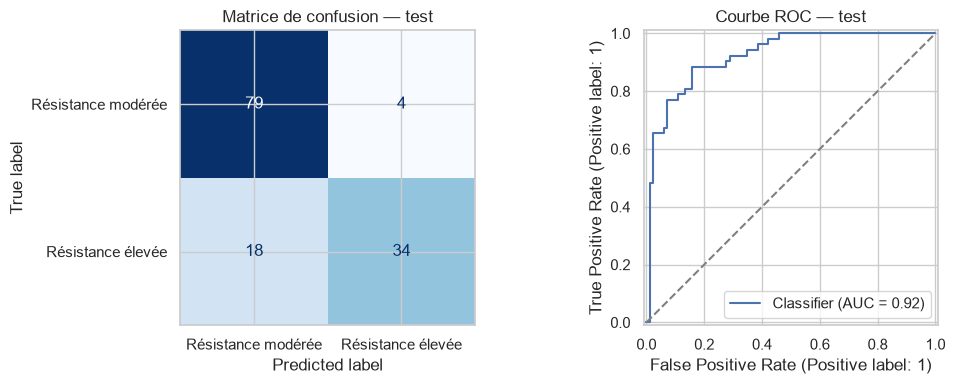

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions["Modèle retenu"]["pred"],
    display_labels=["Résistance modérée", "Résistance élevée"],
    cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title("Matrice de confusion — test")
RocCurveDisplay.from_predictions(
    y_test, test_predictions["Modèle retenu"]["proba"], ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("Courbe ROC — test")
plt.tight_layout()
plt.show()


## 7. Quelles variables aident le modèle ?

**Principe :** mélanger une variable, puis mesurer la baisse de performance. Plus cette baisse est grande, plus le modèle s'appuie sur la variable.

**À lire sur le graphique :** les douze premières variables et la variabilité entre permutations. Des variables corrélées peuvent se remplacer et masquer leur importance individuelle.

Cette lecture décrit des associations prédictives, sans prouver une causalité. Elle ne sert pas à relancer la sélection sur le test.

,variable,importance moyenne,écart-type
6,Chromium concentration,0.170,0.022
5,Nickel concentration,0.032,0.013
9,Copper concentration,0.023,0.014
2,Manganese concentration,0.018,0.025
24,Post weld heat treatment time,0.012,0.011
1,Silicon concentration,0.008,0.017
7,Molybdenum concentration,0.006,0.009
3,Sulphur concentration,0.002,0.005
13,Aluminium concentration,0.002,0.005
21,Interpass temperature,0.002,0.004


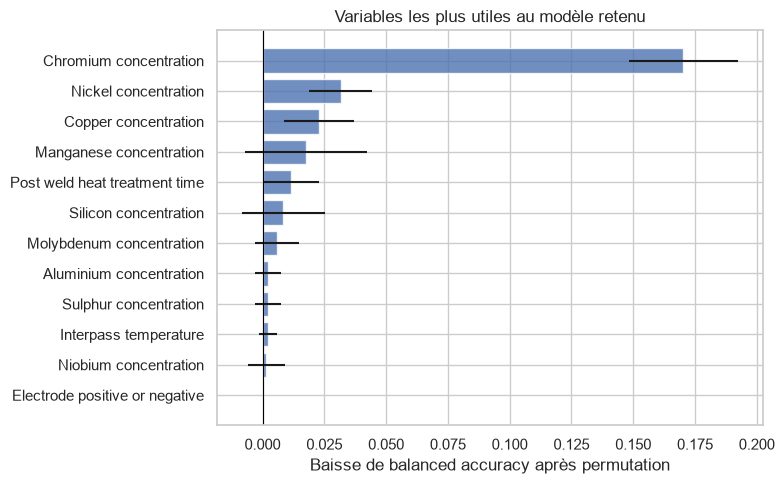

In [33]:
importance = permutation_importance(
    final_model, X_test, y_test, scoring="balanced_accuracy",
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_df = (
    pd.DataFrame({
        "variable": PREDICTOR_COLUMNS,
        "importance moyenne": importance.importances_mean,
        "écart-type": importance.importances_std,
    })
    .sort_values("importance moyenne", ascending=False)
)
display(importance_df.head(12).round(3))

top = importance_df.head(12).sort_values("importance moyenne")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    top["variable"], top["importance moyenne"],
    xerr=top["écart-type"], alpha=.8,
)
ax.axvline(0, color="black", lw=.8)
ax.set(
    xlabel="Baisse de balanced accuracy après permutation",
    title="Variables les plus utiles au modèle retenu",
)
plt.tight_layout()
plt.show()


## 8. Vérifier le protocole

**Dernier contrôle :** identifiants séparés, propriétés cibles absentes de X et labels alignés sur les lignes.

In [34]:
assert set(train_df[ID_COL]).isdisjoint(set(test_df[ID_COL]))
assert ID_COL not in PREDICTOR_COLUMNS
assert not set(EXCLUDED_OUTPUTS).intersection(PREDICTOR_COLUMNS)
assert y_train.index.equals(train_df.index)
assert y_test.index.equals(test_df.index)
assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}

for fit_pos, valid_pos in cv_splits:
    fit_groups = set(groups_train.iloc[fit_pos])
    valid_groups = set(groups_train.iloc[valid_pos])
    assert fit_groups.isdisjoint(valid_groups)

print("Contrôles validés : groupes séparés et sorties absentes de X.")


Contrôles validés : groupes séparés et sorties absentes de X.


## Que retenir des résultats ?

1. **Apprentissage :** comparer le meilleur score de validation à celui du modèle naïf (0,50).
2. **Généralisation :** lire le score du test et le rappel de la classe résistante. La matrice montre les erreurs concrètes.
3. **Interprétation :** identifier les variables sur lesquelles le modèle s'appuie.

La performance concerne les soudures disposant des quatre propriétés mécaniques et le découpage retenu. Les deux profils ayant été choisis lors de l'exploration du notebook 4, l'évaluation est conditionnelle à ce choix.

La prochaine étape métier sera de relier ce profil de résistance aux exigences de l'application, notamment en matière de ductilité.